# Modèle 1 — Détection du début de crise (crise / pas crise)

**Question :** toutes les 5 secondes, à partir des seuls capteurs (accéléromètre + fréquence cardiaque), **la crise a-t-elle commencé ?** Si oui, la voiture ralentit, s'arrête et prévient les proches.

**Modèle retenu :** HistGradientBoosting, **8 features**, évalué sur des patients jamais vus.

| Résultat (patients jamais vus) | Valeur |
|---|---|
| AUC | 0,851 |
| Crises détectées (5 % de fausses alarmes) | 99,2 % |
| Latence médiane | 14 s |

**Plan**
1. Chargement des données
2. Labels : position de chaque bloc par rapport à la crise
3. Features par bloc de 5 s
4. Corrélation et choix des 8 features
5. Entraînement + évaluation *leave-patient-out*
6. Métriques « voiture » : % de crises détectées, latence, fausses alarmes
7. Métriques complètes (AUC, precision, recall, F1, kappa, MCC…)
8. Importance des features
9. Modèle final + sauvegarde `seizure_detection_8features.pkl`
10. Prédiction en temps réel (simulation)

> **Installation** (dans un environnement virtuel) :
> ```
> python -m venv .venv
> .venv\Scripts\activate        # Windows   (Linux/Mac : source .venv/bin/activate)
> pip install numpy pandas scikit-learn matplotlib seaborn joblib jupyter
> ```
> **Données :** `osdb_3min_allSeizures.json(.gz)` est lu dans le dossier partagé `AI/datasets/` et le modèle est sauvegardé dans `MyDrive/AI_outputs/seizure_detection/` (voir la cellule 0).

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
import os
p = "/content/drive/MyDrive/AI"
print("exists:", os.path.exists(p), "| shortcut:", os.path.islink(p))
print(os.listdir(p) if os.path.isdir(p) else os.listdir("/content/drive/MyDrive"))

Mounted at /content/drive
exists: True | shortcut: True
['testing notebooks', "Team's workspace", 'infosession ppt', 'first session record', 'sensors from datasets', 'XAI', 'datasets']


## 0. Chemins (dossier partagé « AI »)

À exécuter en premier : monte Google Drive, trouve le dossier partagé `AI` et prépare le dossier de sortie dans votre Drive.

In [2]:
# ===== 0. CHEMINS DU PROJET : exécuter cette cellule en premier =====
# Données : lues dans le dossier partagé « AI » (AI/datasets/), en lecture seule.
# Résultats : écrits dans VOTRE Drive, dans MyDrive/AI_outputs/<NOTEBOOK>.
#
# Une seule fois par personne, dans Google Drive (navigateur) :
#   « Partagés avec moi » > clic droit sur « AI » > Organiser > Ajouter un raccourci > « Mon Drive »
import glob, os
from pathlib import Path

NOTEBOOK = "seizure_detection"          # sous-dossier de sortie de ce notebook
BESOINS = ['seizure']              # datasets utilisés par ce notebook (clés de DATA ci-dessous)
AI_ROOT_MANUEL = None              # sur un PC uniquement, ex. r"G:\Mon Drive\AI" ; sinon laisser None

try:                               # Colab : monter Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
except ImportError:                # Jupyter sur un PC
    EN_COLAB = False


def trouver_racine_ai(nom="AI"):
    """Le dossier « AI » qui contient datasets/ et XAI/ (raccourci ou dossier dans Mon Drive, ou Drive partagé)."""
    ok = lambda p: (Path(p) / "datasets").is_dir() and (Path(p) / "XAI").is_dir()
    if AI_ROOT_MANUEL:
        return Path(AI_ROOT_MANUEL)
    for base in ("MyDrive", "Shareddrives"):
        for niveaux in range(4):                       # AI à la racine, puis jusqu'à 3 dossiers plus bas
            for p in sorted(glob.glob(f"/content/drive/{base}/{'*/' * niveaux}{nom}")):
                if ok(p):
                    return Path(p)
    for d in (Path.cwd(), *Path.cwd().parents):        # PC : notebook ouvert depuis le dossier AI synchronisé
        for p in (d, d / nom):
            if ok(p):
                return p
    raise FileNotFoundError(
        f"Dossier « {nom} » introuvable. Dans Google Drive : « Partagés avec moi » > clic droit sur « {nom} » "
        "> Organiser > Ajouter un raccourci > « Mon Drive », puis relancer cette cellule. "
        "Sur un PC : renseigner AI_ROOT_MANUEL.")


def _dossiers(racine, profondeur):
    """`racine` puis ses sous-dossiers, du moins profond au plus profond (dossiers cachés ignorés)."""
    niveau = [Path(racine)] if Path(racine).is_dir() else []
    for n in range(profondeur + 1):
        yield from niveau
        if n == profondeur:
            return
        suivant = []
        for d in niveau:
            try:
                with os.scandir(d) as entrees:
                    suivant += sorted(Path(e.path) for e in entrees
                                      if e.is_dir() and not e.name.startswith((".", "__")))
            except OSError:
                pass
        niveau = suivant


def trouver_fichier(noms, *dossiers, profondeur=3):
    """Premier fichier appelé `noms` (un nom ou une liste) dans `dossiers` ou leurs sous-dossiers."""
    noms = [noms] if isinstance(noms, str) else list(noms)
    for racine in dossiers:
        for d in _dossiers(racine, profondeur):
            for nom in noms:
                if (d / nom).is_file():
                    return d / nom
    raise FileNotFoundError(f"{' / '.join(noms)} introuvable dans : " + " ; ".join(map(str, dossiers)))


def trouver_dossier_contenant(sous_dossier, *dossiers, profondeur=3):
    """Premier dossier (dans `dossiers` ou leurs sous-dossiers) qui contient `sous_dossier`."""
    for racine in dossiers:
        for d in _dossiers(racine, profondeur):
            if (d / sous_dossier).is_dir():
                return d
    raise FileNotFoundError(f"Aucun dossier contenant {sous_dossier}/ dans : " + " ; ".join(map(str, dossiers)))


AI_ROOT = trouver_racine_ai()
DATASETS = AI_ROOT / "datasets"


def dataset(*mots, exact=False):
    """Sous-dossier de datasets/ dont le nom contient l'un des mots (ou vaut ce mot si exact=True), sans tenir compte des majuscules."""
    dossiers = sorted(d for d in DATASETS.iterdir() if d.is_dir())
    for mot in mots:
        for d in dossiers:
            if (d.name.lower() == mot.lower()) if exact else (mot.lower() in d.name.lower()):
                return d
    return DATASETS / mots[0]      # introuvable : signalé « MANQUANT » ci-dessous


DATA = {
    "seizure":     dataset("seizure"),                               # seizure dataset (release from github)
    "stroke":      dataset("neuroface", "stroke"),                   # NeuroFace Stroke dataset
    "cardiac":     dataset("heart"),                                 # heart diseasing dataset
    "cardiac_csv": dataset("cardiac_arrest_csv", "data", exact=True),  # CSV du modèle arrêt cardiaque
}

# Le dossier partagé est en lecture seule : chacun écrit ses résultats dans son propre Drive
SORTIES = (Path("/content/drive/MyDrive") if EN_COLAB else Path.cwd()) / "AI_outputs" / NOTEBOOK
SORTIES.mkdir(parents=True, exist_ok=True)

print("Dossier AI :", AI_ROOT)
for cle in BESOINS:
    print(f"  {'OK      ' if DATA[cle].is_dir() else 'MANQUANT'} DATA[{cle!r}] = {DATA[cle]}")
print("Sorties    :", SORTIES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossier AI : /content/drive/MyDrive/AI
  OK       DATA['seizure'] = /content/drive/MyDrive/AI/datasets/seizure dataset (release from github)
Sorties    : /content/drive/MyDrive/AI_outputs/seizure_detection


In [3]:
import gzip, json, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, log_loss,
                             roc_curve, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")

# Données : cherchées dans AI/datasets/<dossier seizure>/ et ses sous-dossiers (cellule 0)
DATA_PATH = str(trouver_fichier(["osdb_3min_allSeizures.json.gz", "osdb_3min_allSeizures.json"], DATA["seizure"]))
MODELE_PKL = SORTIES / "seizure_detection_8features.pkl"   # modèle sauvegardé dans VOTRE Drive
print("Données :", DATA_PATH)
FS = 25      # fréquence d'échantillonnage de l'accéléromètre (Hz) -> 125 valeurs par bloc de 5 s
PRE = 30     # durée (s) de la zone "préictale" juste avant la crise (analyse uniquement)
SEED = 0

Données : /content/drive/MyDrive/AI/datasets/seizure dataset (release from github)/osdb_3min_allSeizures.json.gz


## 1. Chargement des données

Chaque **événement** = environ 3 minutes autour d'une crise, découpées en blocs de 5 s (`rawData` = 125 valeurs d'accéléromètre, `hr` = fréquence cardiaque). `seizureTimes` donne le début et la fin de la crise.

In [4]:
opener = gzip.open if DATA_PATH.endswith(".gz") else open
with opener(DATA_PATH, "rt", encoding="utf-8") as f:
    events = json.load(f)
print(f"{len(events)} événements")

summary = pd.DataFrame([{
    "id": ev["id"], "user": ev["userId"], "type": ev["subType"] or "Unknown",
    "n_blocs": len(ev["datapoints"]),
    "debut_crise": json.loads(ev["seizureTimes"])[0],
    "fin_crise": json.loads(ev["seizureTimes"])[1],
} for ev in events])

print("Types de crise :\n", summary["type"].value_counts(), "\n")
print("Nombre de patients :", summary["user"].nunique())
print("Événements par patient (top 5) :\n", summary["user"].value_counts().head())

522 événements
Types de crise :
 type
Tonic-Clonic    288
Other           137
Aura             69
Suspected        24
Unknown           4
Name: count, dtype: int64 

Nombre de patients : 33
Événements par patient (top 5) :
 user
1643    227
39      128
45       52
733      45
487       9
Name: count, dtype: int64


## 2. Labels : où se situe chaque bloc par rapport à la crise

| `t` (temps du bloc) | label |
|---|---|
| avant `début − 30 s` | `interictal` |
| entre `début − 30 s` et `début` | `preictal` |
| entre `début` et `fin` | `ictal` (**crise en cours**) |
| après `fin` | `postictal` |

La **cible** est binaire : `ictal` (1) ou non (0).

In [5]:
def label_of(t, s0, s1, pre=PRE):
    if s0 <= t <= s1:      return "ictal"
    if s0 - pre <= t < s0: return "preictal"
    if t > s1:             return "postictal"
    return "interictal"

## 3. Features : résumer chaque bloc de 5 s en quelques chiffres

In [6]:
def accel_features(raw, fs=FS):
    """Features d'un bloc d'accéléromètre (125 valeurs)."""
    x = np.asarray(raw, float)
    x = x - x.mean()                                   # on retire la gravité / l'orientation
    spec = np.abs(np.fft.rfft(x)) ** 2                 # puissance par fréquence
    freqs = np.fft.rfftfreq(len(x), 1 / fs)
    total = spec[1:].sum() + 1e-9
    feats = {
        "acc_std":  x.std(),                           # intensité du mouvement
        "acc_rng":  np.ptp(x),                         # amplitude max-min
        "acc_mad":  np.abs(np.diff(x)).mean(),         # "secousses" d'un échantillon à l'autre
        "acc_kurt": (x**4).mean() / (x.var()**2 + 1e-9),  # présence de pics
        "logpow":   np.log1p(total),                   # énergie totale
        "domfreq":  freqs[1:][spec[1:].argmax()],      # fréquence dominante
    }
    # part de l'énergie dans 3 bandes — les convulsions sont typiquement dans 3–8 Hz
    for lo, hi in [(0.5, 3), (3, 8), (8, 12.5)]:
        feats[f"p_{lo}_{hi}"] = spec[(freqs >= lo) & (freqs < hi)].sum() / total
    return feats

In [7]:
rows = []
for ev in events:
    t0 = datetime.fromisoformat(ev["dataTime"])
    s0, s1 = json.loads(ev["seizureTimes"])
    for p in ev["datapoints"]:
        if len(p.get("rawData") or []) != 125:
            continue
        t = (datetime.fromisoformat(p["dataTime"]) - t0).total_seconds()
        r = {"event": ev["id"], "user": ev["userId"], "type": ev["subType"] or "Unknown",
             "t": t, "t_rel": t - s0, "label": label_of(t, s0, s1),
             "hr": p["hr"] if (p.get("hr") or -1) > 0 else np.nan}
        r.update(accel_features(p["rawData"]))
        rows.append(r)

df = pd.DataFrame(rows)
# blocs à horodatage dupliqué (événements fusionnés qui se chevauchent) -> retirés
df = df.drop_duplicates(["event", "t"], keep=False).sort_values(["event", "t"], kind="stable").reset_index(drop=True)
print(df.shape)

(20380, 16)


**Features temporelles causales** : on regarde l'évolution sur les 15 dernières secondes, sans jamais utiliser le futur, pour que le modèle puisse tourner en temps réel.

In [8]:
# Features temporelles CAUSALES : uniquement le passé (15 dernières secondes = 3 blocs)
g_ev = df.groupby("event")
for c in ["hr", "acc_std", "p_3_8", "logpow"]:
    df[c + "_d15"] = df[c] - g_ev[c].shift(3)                                         # variation sur 15 s
    df[c + "_m15"] = g_ev[c].transform(lambda s: s.rolling(3, min_periods=1).mean())  # moyenne sur 15 s
df["hr_base"] = g_ev["hr"].transform(lambda s: s.expanding().median())   # rythme "normal" de la personne jusqu'ici
df["hr_rel"] = df["hr"] - df["hr_base"]
print(df["label"].value_counts())

FEATURES_20 = [c for c in df.columns if c not in ("event", "user", "type", "t", "t_rel", "label")]
print(len(FEATURES_20), "features :", FEATURES_20)

label
ictal         13300
postictal      3194
preictal       2196
interictal     1690
Name: count, dtype: int64
20 features : ['hr', 'acc_std', 'acc_rng', 'acc_mad', 'acc_kurt', 'logpow', 'domfreq', 'p_0.5_3', 'p_3_8', 'p_8_12.5', 'hr_d15', 'hr_m15', 'acc_std_d15', 'acc_std_m15', 'p_3_8_d15', 'p_3_8_m15', 'logpow_d15', 'logpow_m15', 'hr_base', 'hr_rel']


## 4. Corrélation et choix des 8 features

Beaucoup des 20 features disent la même chose (ex. `acc_std` et `logpow` corrélées à 1,00). On garde **un représentant par famille** : moins de redondance, moins de sur-apprentissage.

In [ ]:
corr_df = df[FEATURES_20].copy()
corr_df["crise"] = (df["label"] == "ictal").astype(int)
corr = corr_df.corr(method="spearman")      # Spearman : robuste aux pics de mouvement

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(13, 11))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7})
plt.title("Matrice de corrélation (Spearman) des features + cible")
plt.tight_layout(); plt.show()

corr["crise"].drop("crise").sort_values().plot.barh(figsize=(7, 6), color="tab:blue")
plt.axvline(0, color="k", lw=0.8); plt.title("Corrélation de chaque feature avec 'crise en cours'")
plt.tight_layout(); plt.show()

corr_f = corr.drop(index="crise", columns="crise")
pairs = corr_f.where(np.triu(np.ones_like(corr_f, dtype=bool), k=1)).stack()
print("Paires redondantes (|corr| > 0.85) :\n", pairs[pairs.abs() > 0.85].sort_values(key=abs, ascending=False).round(2))

In [ ]:
FEATURES_8 = ["acc_std_m15", "acc_std_d15", "acc_kurt",      # intensité du mouvement (niveau, variation, pics)
              "p_3_8_m15", "p_8_12.5", "domfreq",            # rythme du mouvement
              "hr_rel", "hr_d15"]                            # cœur (relatif à la personne, variation)

## 5. Entraînement + évaluation *leave-patient-out*

Séparation **par patient** (`GroupKFold` sur `user`) : le modèle est toujours testé sur des personnes qu'il n'a **jamais vues**. On compare la version 20 features et la version 8 features retenue.

In [ ]:
y = (df["label"] == "ictal").astype(int).values
groups = df["user"].values

def make_model():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                          class_weight="balanced", random_state=SEED)

def cv_proba(feature_list, verbose=False):
    """Probabilités out-of-fold : chaque bloc est prédit par un modèle qui n'a jamais vu son patient."""
    proba = np.zeros(len(df))
    for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(df, y, groups)):
        m = make_model().fit(df[feature_list].iloc[tr], y[tr])
        proba[te] = m.predict_proba(df[feature_list].iloc[te])[:, 1]
        if verbose:
            print(f"Fold {fold} : AUC = {roc_auc_score(y[te], proba[te]):.3f}  ({len(set(groups[te]))} patients de test)")
    return proba

df["proba_20"] = cv_proba(FEATURES_20)
print("Modèle retenu (8 features), par fold :")
df["proba_8"] = cv_proba(FEATURES_8, verbose=True)
print(f"\nAUC 20 features = {roc_auc_score(y, df['proba_20']):.3f}")
print(f"AUC  8 features = {roc_auc_score(y, df['proba_8']):.3f}")

Modèle retenu (8 features), par fold :
Fold 0 : AUC = 0.884  (1 patients de test)
Fold 1 : AUC = 0.859  (1 patients de test)
Fold 2 : AUC = 0.928  (7 patients de test)
Fold 3 : AUC = 0.806  (8 patients de test)
Fold 4 : AUC = 0.852  (16 patients de test)

AUC 20 features = 0.848
AUC  8 features = 0.851


## 6. Métriques « voiture »

- **% de crises détectées**
- **latence** : secondes entre le début de la crise et l'alarme
- **fausses alarmes** : % de blocs *avant* la crise où l'alarme sonne à tort

**Règle d'alarme** : probabilité au-dessus du seuil **2 blocs de suite** (10 s).

In [ ]:
def evaluate(df, thr, col="proba_8", n_consec=2):
    lat, fa, n_pre = [], 0, 0
    for _, g in df.groupby("event"):
        g = g.sort_values("t")
        above = g[col] > thr
        alarm = above.copy()
        for k in range(1, n_consec):
            alarm &= above.shift(k, fill_value=False)
        pre = g["label"].isin(["interictal", "preictal"])
        fa += (alarm & pre).sum(); n_pre += pre.sum()
        hit = g[alarm & (g["label"] == "ictal")]
        lat.append(hit["t_rel"].iloc[0] if len(hit) else np.nan)
    lat = np.array(lat)
    return {"seuil": thr, "fausses_alarmes": fa / n_pre,
            "detectees": np.mean(~np.isnan(lat)), "latence_mediane_s": np.nanmedian(lat),
            "detectees_<=20s": np.mean(lat <= 20)}

def threshold_for_fa(df, target_fa, col="proba_8"):
    """Seuil qui donne le taux de fausses alarmes voulu (dichotomie)."""
    lo, hi = 0.0, 1.0
    for _ in range(25):
        mid = (lo + hi) / 2
        if evaluate(df, mid, col)["fausses_alarmes"] > target_fa: lo = mid
        else: hi = mid
    return hi

rows_cmp = []
for name, col in [("20 features", "proba_20"), ("8 features (retenu)", "proba_8")]:
    for fa in [0.02, 0.05, 0.10]:
        r = evaluate(df, threshold_for_fa(df, fa, col=col), col=col)
        r.update({"modele": name, "AUC": roc_auc_score(y, df[col])})
        rows_cmp.append(r)

comp = pd.DataFrame(rows_cmp)[["modele", "AUC", "seuil", "fausses_alarmes", "detectees", "latence_mediane_s", "detectees_<=20s"]]
comp.style.format({"AUC": "{:.3f}", "seuil": "{:.3f}", "fausses_alarmes": "{:.1%}", "detectees": "{:.1%}",
                   "latence_mediane_s": "{:.0f}", "detectees_<=20s": "{:.1%}"})

,modele,AUC,seuil,fausses_alarmes,detectees,latence_mediane_s,detectees_<=20s
0,20 features,0.848,0.920,2.0%,73.8%,24,34.5%
1,20 features,0.848,0.736,5.0%,96.4%,12,73.0%
2,20 features,0.848,0.485,10.0%,99.6%,10,86.2%
3,8 features (retenu),0.851,0.857,2.0%,87.5%,20,46.7%
4,8 features (retenu),0.851,0.700,5.0%,99.2%,14,75.9%
5,8 features (retenu),0.851,0.497,10.0%,99.6%,10,87.5%


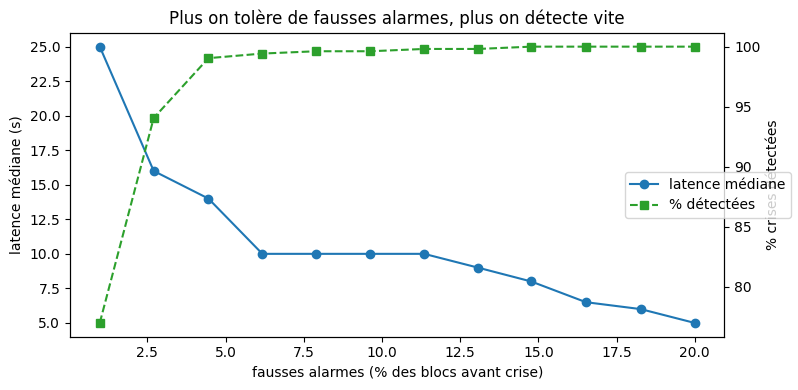

In [ ]:
# Compromis vitesse / fausses alarmes (modèle retenu)
fas = np.linspace(0.01, 0.2, 12)
curve = pd.DataFrame([evaluate(df, threshold_for_fa(df, f)) for f in fas])
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(curve["fausses_alarmes"] * 100, curve["latence_mediane_s"], "o-", label="latence médiane")
ax1.set_xlabel("fausses alarmes (% des blocs avant crise)"); ax1.set_ylabel("latence médiane (s)")
ax2 = ax1.twinx()
ax2.plot(curve["fausses_alarmes"] * 100, curve["detectees"] * 100, "s--", color="tab:green", label="% détectées")
ax2.set_ylabel("% crises détectées")
fig.legend(loc="center right"); plt.title("Plus on tolère de fausses alarmes, plus on détecte vite")
plt.tight_layout(); plt.show()

## 7. Métriques complètes du modèle retenu

Calculées sur les probabilités *out-of-fold* (patients jamais vus), au seuil 0,5 puis au **seuil voiture** (≈ 5 % de fausses alarmes).


DÉTECTION — 8 features, seuil 0,5
Accuracy             0.787
Balanced accuracy    0.780
Precision (macro)    0.766
Recall (macro)       0.780
F1 (macro)           0.771
F1 (pondéré)         0.789
AUC ROC              0.851
Cohen's kappa        0.543
MCC                  0.545
Log loss             0.496

Par classe :
               precision    recall  f1-score   support

   pas crise      0.671     0.757     0.711      7080
       crise      0.861     0.802     0.831     13300

    accuracy                          0.787     20380
   macro avg      0.766     0.780     0.771     20380
weighted avg      0.795     0.787     0.789     20380



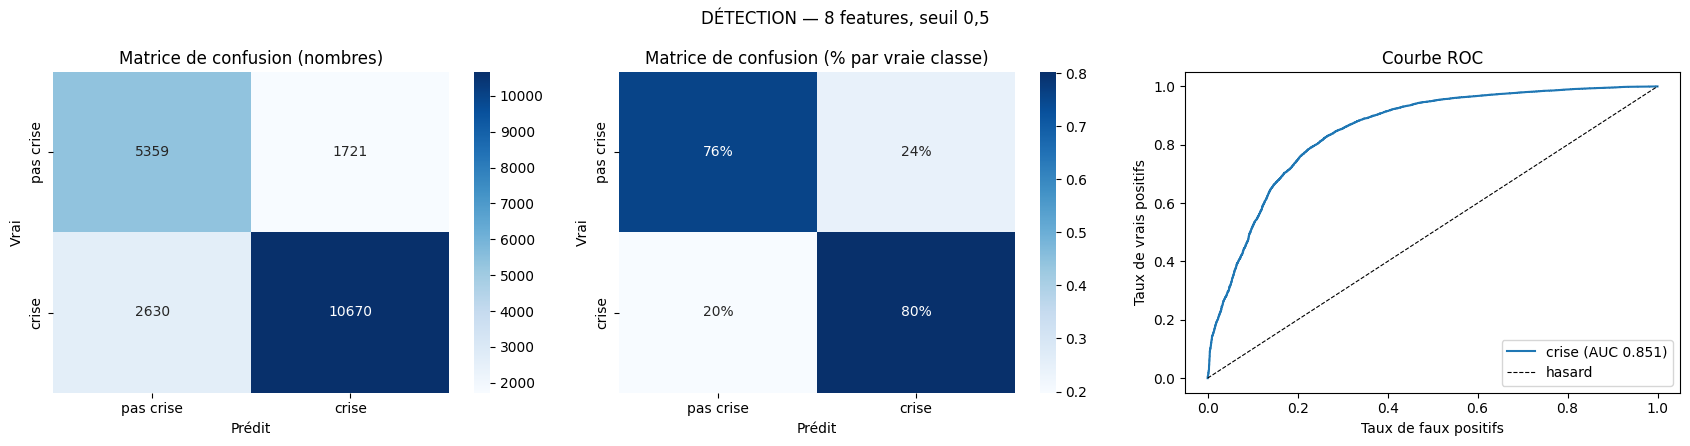


DÉTECTION — 8 features, seuil voiture 0.700 (≈ 5 % de fausses alarmes)
Accuracy             0.737
Balanced accuracy    0.762
Precision (macro)    0.737
Recall (macro)       0.762
F1 (macro)           0.731
F1 (pondéré)         0.744
AUC ROC              0.851
Cohen's kappa        0.475
MCC                  0.498
Log loss             0.496

Par classe :
               precision    recall  f1-score   support

   pas crise      0.585     0.841     0.690      7080
       crise      0.890     0.682     0.772     13300

    accuracy                          0.737     20380
   macro avg      0.737     0.762     0.731     20380
weighted avg      0.784     0.737     0.744     20380



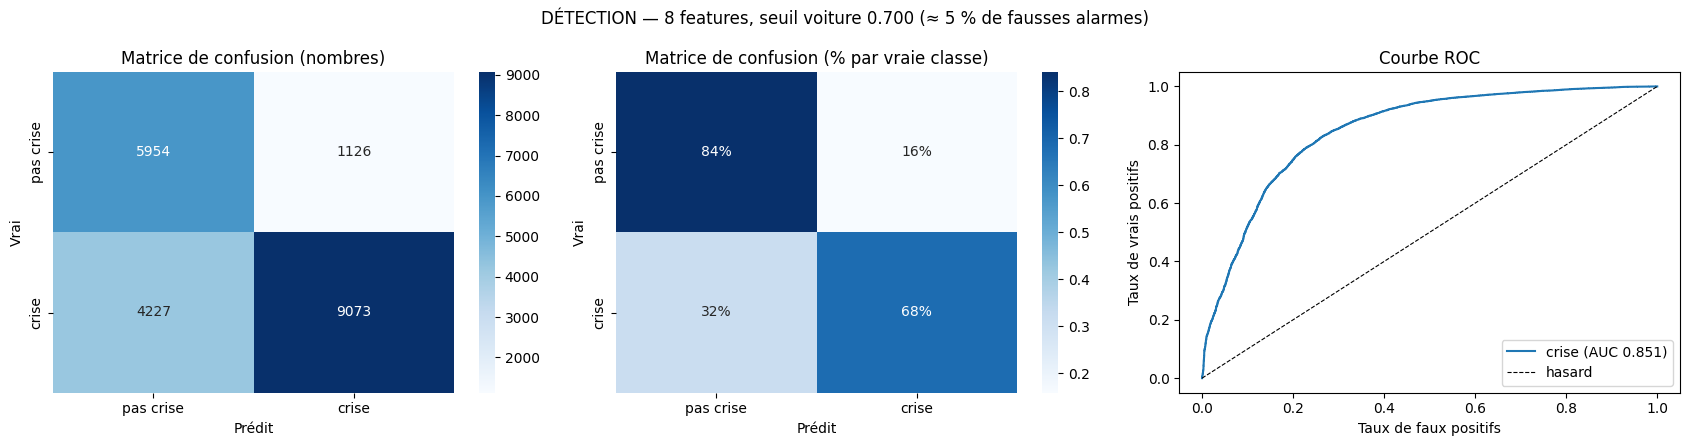

In [ ]:
def rapport_complet(y_true, proba, classes, titre, seuil=0.5):
    y_true = np.asarray(y_true)
    pred = np.where(proba[:, 1] > seuil, classes[1], classes[0])
    print(f"\n{'=' * 70}\n{titre}\n{'=' * 70}")
    print(pd.Series({
        "Accuracy":          accuracy_score(y_true, pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "Precision (macro)": precision_score(y_true, pred, average="macro"),
        "Recall (macro)":    recall_score(y_true, pred, average="macro"),
        "F1 (macro)":        f1_score(y_true, pred, average="macro"),
        "F1 (pondéré)":      f1_score(y_true, pred, average="weighted"),
        "AUC ROC":           roc_auc_score(y_true == classes[1], proba[:, 1]),
        "Cohen's kappa":     cohen_kappa_score(y_true, pred),
        "MCC":               matthews_corrcoef(y_true, pred),
        "Log loss":          log_loss(y_true == classes[1], proba[:, 1]),
    }).round(3).to_string())
    print("\nPar classe :\n", classification_report(y_true, pred, labels=classes, digits=3))

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    cm = confusion_matrix(y_true, pred, labels=classes)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0])
    ax[0].set(title="Matrice de confusion (nombres)", xlabel="Prédit", ylabel="Vrai")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".0%", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=ax[1])
    ax[1].set(title="Matrice de confusion (% par vraie classe)", xlabel="Prédit", ylabel="Vrai")
    fpr, tpr, _ = roc_curve(y_true == classes[1], proba[:, 1])
    ax[2].plot(fpr, tpr, label=f"{classes[1]} (AUC {roc_auc_score(y_true == classes[1], proba[:, 1]):.3f})")
    ax[2].plot([0, 1], [0, 1], "k--", lw=0.8, label="hasard")
    ax[2].set(title="Courbe ROC", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs"); ax[2].legend()
    fig.suptitle(titre); plt.tight_layout(); plt.show()

p8 = df["proba_8"].values
y_det = np.where(y == 1, "crise", "pas crise")
rapport_complet(y_det, np.c_[1 - p8, p8], ["pas crise", "crise"], "DÉTECTION — 8 features, seuil 0,5")

SEUIL_8 = threshold_for_fa(df, 0.05, col="proba_8")
rapport_complet(y_det, np.c_[1 - p8, p8], ["pas crise", "crise"],
                f"DÉTECTION — 8 features, seuil voiture {SEUIL_8:.3f} (≈ 5 % de fausses alarmes)", seuil=SEUIL_8)

## 8. Quelles features comptent le plus ?

*Permutation importance* : on mélange une feature et on mesure la baisse d'AUC (calculé sur un fold pour aller vite).

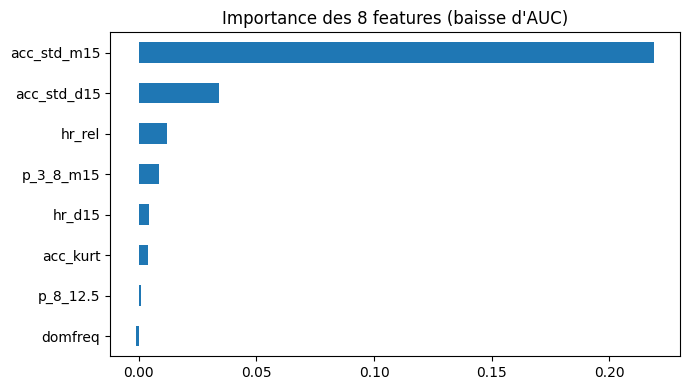

In [ ]:
X8 = df[FEATURES_8]
tr, te = next(GroupKFold(n_splits=5).split(X8, y, groups))
m = make_model().fit(X8.iloc[tr], y[tr])
sub = np.random.RandomState(SEED).choice(te, size=min(3000, len(te)), replace=False)
pi = permutation_importance(m, X8.iloc[sub], y[sub], scoring="roc_auc", n_repeats=5, random_state=SEED)
pd.Series(pi.importances_mean, index=FEATURES_8).sort_values().plot.barh(
    figsize=(7, 4), title="Importance des 8 features (baisse d'AUC)")
plt.tight_layout(); plt.show()

## 9. Modèle final + sauvegarde

Le modèle final est entraîné sur **tous les patients**. Le fichier `.pkl` contient le modèle, la liste exacte des features, le seuil et la règle d'alarme.

In [ ]:
modele_final_8 = make_model().fit(df[FEATURES_8], y)

bundle = {
    "model": modele_final_8,
    "features": FEATURES_8,            # ordre exact des colonnes attendu par le modèle
    "threshold": SEUIL_8,              # seuil d'alarme (≈ 5 % de fausses alarmes)
    "n_consec": 2,                     # alarme si seuil dépassé 2 blocs de suite (10 s)
    "fs": FS,                          # 25 Hz, 125 valeurs par bloc de 5 s
    "auc_cv": roc_auc_score(y, df["proba_8"]),
    "sklearn_version": sklearn.__version__,
    "date": datetime.now().isoformat(timespec="seconds"),
}
joblib.dump(bundle, MODELE_PKL)
print("Modèle sauvegardé :", MODELE_PKL)
print(f"  seuil = {SEUIL_8:.3f} | AUC (patients jamais vus) = {bundle['auc_cv']:.3f}")

Modèle sauvegardé : /content/drive/MyDrive/AI_outputs/seizure_detection/seizure_detection_8features.pkl
  seuil = 0.700 | AUC (patients jamais vus) = 0.851


## 10. Prédiction en temps réel (simulation)

`SeizureMonitor` reçoit un bloc de 5 s à la fois, comme dans la voiture. La démo rejoue une crise du jeu de données (ce patient a servi à l'entraînement : c'est une démo du fonctionnement, pas une évaluation).

In [ ]:
class SeizureMonitor:
    """Simule le fonctionnement dans la voiture : un bloc de 5 s à la fois."""
    def __init__(self, path=MODELE_PKL):
        b = joblib.load(path)
        self.model, self.features, self.thr = b["model"], b["features"], b["threshold"]
        self.n_consec = b["n_consec"]
        self.history = []          # features des blocs passés
        self.above = []            # dépassements de seuil passés

    def update(self, raw_accel, hr):
        f = accel_features(raw_accel)
        f["hr"] = hr if (hr is not None and hr > 0) else np.nan
        self.history.append(f)
        h = pd.DataFrame(self.history)
        for c in ["hr", "acc_std", "p_3_8", "logpow"]:
            f[c + "_d15"] = h[c].iloc[-1] - h[c].iloc[-4] if len(h) >= 4 else np.nan
            f[c + "_m15"] = h[c].iloc[-3:].mean()
        f["hr_base"] = h["hr"].median()
        f["hr_rel"] = f["hr"] - f["hr_base"]
        p = self.model.predict_proba(pd.DataFrame([f])[self.features])[0, 1]
        self.above.append(p > self.thr)
        alarm = len(self.above) >= self.n_consec and all(self.above[-self.n_consec:])
        return p, alarm

mon = SeizureMonitor()
ev = events[0]; t0 = datetime.fromisoformat(ev["dataTime"]); s0, s1 = json.loads(ev["seizureTimes"])
for p in ev["datapoints"]:
    t = (datetime.fromisoformat(p["dataTime"]) - t0).total_seconds() - s0
    proba, alarm = mon.update(p["rawData"], p.get("hr"))
    print(f"t = {t:+6.0f} s | P(crise) = {proba:.2f} | {'🚨 ALERTE : arrêt + appel des proches' if alarm else ''}")
    if alarm:
        break

t =    -34 s | P(crise) = 0.07 | 
t =    -29 s | P(crise) = 0.06 | 
t =    -24 s | P(crise) = 0.07 | 
t =    -19 s | P(crise) = 0.17 | 
t =    -14 s | P(crise) = 0.16 | 
t =     -9 s | P(crise) = 0.17 | 
t =     -3 s | P(crise) = 0.88 | 
t =     +2 s | P(crise) = 0.80 | 🚨 ALERTE : arrêt + appel des proches


## Limites

- Fausses alarmes mesurées seulement sur les minutes **avant** chaque crise, pas sur des heures de conduite réelle.
- Probabilités mal calibrées (log loss élevé) : le classement est bon, la valeur affichée n'est pas une probabilité exacte.
- Détecte le **début** de la crise, pas la phase pré-ictale.
- Deux patients (1643 et 39) représentent ~68 % des événements.
- Données issues d'une montre, à transposer vers des capteurs embarqués dans la voiture.